# 03 - Baseline

Objectif : un modèle simple, lisible et défendable, qui sert de référence pour toutes les idées de l'étape d.

On utilise le découpage figé à l'étape b (`artifacts/`), donc `02_validation.ipynb` doit avoir tourné avant.
Métrique principale : accuracy sur les dates récentes de validation, moyenne des 8 plis.
Chaque modèle évalué ici est inscrit dans `artifacts/journal.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

import utils
from utils import RET, SV, compare

SEED = 42
plt.rcParams.update({'figure.figsize': (9, 3.4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .25, 'font.size': 10})
BLUE, GREY = '#2a6fdb', '#8a8f98'

X, y, Xt = utils.load_data()
ch, folds = utils.load_split()
recent = utils.recent_regime(X, ch)
is_recent = X.TS.map(recent).to_numpy()
up = (y > 0).to_numpy()

# masques de lignes par pli, calculés une fois
masks = [(X.TS.isin(f['train']).to_numpy(), X.TS.isin(f['val']).to_numpy()) for f in folds]
print(len(folds), 'plis,', int(recent.sum()), 'dates récentes')

8 plis, 1493 dates récentes


In [2]:
def evaluate(fit_predict):
    # fit_predict(train_mask, val_mask) -> probabilité ou score, positif = hausse prédite
    recent_scores, all_scores = [], []
    for tr, va in masks:
        pred = np.asarray(fit_predict(tr, va))
        hit = (pred > 0) == up[va]
        recent_scores.append(hit[is_recent[va]].mean())
        all_scores.append(hit.mean())
    return np.array(recent_scores), np.array(all_scores)

def show(name, scores):
    r, a = scores
    print(f"{name:28s} récentes {r.mean():.4f} (+/- {r.std(ddof=1) / np.sqrt(len(r)):.4f})   toutes {a.mean():.4f}")

## 1. Les deux références

- **Règle naïve** : prédire le signe du rendement d'hier. Aucun paramètre.
- **Benchmark QRT** : le LightGBM du notebook officiel, avec ses 52 features. Recalculé ici sur nos plis (8 entraînements, une à deux minutes).

In [3]:
naive = evaluate(lambda tr, va: X.RET_1.to_numpy()[va])
show('règle naïve signe(RET_1)', naive)
_ = utils.log_result('naive_ret1', *naive, note='signe du rendement de la veille')

def benchmark_features(df):
    df = df.copy()
    for i in [3, 5, 10, 15, 20]:
        df[f'AVERAGE_PERF_{i}'] = df[RET[:i]].mean(axis=1)
        df[f'ALLOCATIONS_AVERAGE_PERF_{i}'] = df.groupby('TS')[f'AVERAGE_PERF_{i}'].transform('mean')
    df['STD_PERF_20'] = df[RET].std(axis=1)
    df['ALLOCATIONS_STD_PERF_20'] = df.groupby('TS')['STD_PERF_20'].transform('mean')
    return df

FB = benchmark_features(X)
BENCH_FEATS = [c for c in FB.columns if c not in ('TS', 'ALLOCATION', 'GROUP')]
BENCH_PARAMS = dict(objective='mse', seed=SEED, verbosity=-1, learning_rate=1e-2, max_depth=3)

def bench_fit_predict(tr, va):
    model = lgb.train(BENCH_PARAMS, lgb.Dataset(FB.loc[tr, BENCH_FEATS], label=y[tr].to_numpy()), num_boost_round=500)
    return model.predict(FB.loc[va, BENCH_FEATS])

bench = evaluate(bench_fit_predict)
show('benchmark LightGBM', bench)
_ = utils.log_result('benchmark_lgbm', *bench, note='notebook officiel QRT, 52 features')

règle naïve signe(RET_1)     récentes 0.5157 (+/- 0.0012)   toutes 0.5199


benchmark LightGBM           récentes 0.5184 (+/- 0.0014)   toutes 0.5217


## 2. Les features de la baseline

Une dizaine de features, chacune avec une raison d'être (code dans `utils.baseline_features`) :

- `ret1_z`, `mean5_z`, `mean20_z` : rendement d'hier et moyennes sur 5 et 20 jours, **divisés par la vol de la fenêtre**.
  Les allocations ont des vols très différentes (de 0,1 % à plus de 1 % par jour). Sans normalisation, le modèle
  donnerait plus de poids aux allocations volatiles uniquement parce que leurs chiffres sont plus grands.
- `log_vol` : le niveau de risque lui-même.
- `mkt_ret1` : le mouvement moyen de toutes les allocations hier, pour séparer l'effet de marché de l'effet propre.
- `sv1_day` : l'indicateur de jour de la semaine trouvé en EDA.
- `log_turnover` : à quel point l'allocation tourne son portefeuille.
- `group_2..4` : le groupe (le groupe 1 sert de référence).

On n'utilise pas l'identité de l'allocation : c'est une idée de l'étape d, qui demande des précautions contre la fuite.

In [4]:
F = utils.baseline_features(X)
print(F.describe().T[['mean', 'std', 'min', 'max']].round(3))

               mean    std    min    max
ret1_z        0.025  0.999 -4.374  4.519
mean5_z       0.015  0.466 -2.631  2.213
mean20_z      0.010  0.251 -2.178  2.095
log_vol      -6.020  0.458 -7.884 -3.482
mkt_ret1      0.033  0.294 -0.928  0.895
sv1_day       0.195  0.396  0.000  1.000
log_turnover  1.234  1.228  0.000  5.056
group_2       0.256  0.436  0.000  1.000
group_3       0.320  0.467  0.000  1.000
group_4       0.233  0.423  0.000  1.000


## 3. Régression logistique

Pourquoi une logistique et pas une régression sur le rendement : la métrique ne regarde que le signe. Une régression
linéaire sur le rendement serait tirée par les quelques journées extrêmes (kurtosis ~8). La logistique ne voit que
hausse/baisse, exactement ce qui est évalué.

Les features sont standardisées dans le pipeline, et la standardisation est apprise sur le train de chaque pli uniquement.
Pas de réglage d'hyperparamètre : avec plus de 300 000 lignes par pli et 10 features, la régularisation par défaut ne joue presque aucun rôle.

In [5]:
def logit_fit_predict(cols):
    def fp(tr, va):
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        model.fit(F.loc[tr, cols], up[tr])
        return model.predict_proba(F.loc[va, cols])[:, 1] - .5
    return fp

logit_ret1 = evaluate(logit_fit_predict(['ret1_z']))
show('logistique ret1_z seul', logit_ret1)

COLS = list(F.columns)
logit = evaluate(logit_fit_predict(COLS))
show('logistique baseline', logit)
_ = utils.log_result('logit_baseline', *logit, note='10 features utils.baseline_features')

logistique ret1_z seul       récentes 0.5164 (+/- 0.0015)   toutes 0.5201


logistique baseline          récentes 0.5173 (+/- 0.0019)   toutes 0.5219


In [6]:
print('baseline contre règle naïve :', {k: round(float(v), 4) if k != 'retenu' else v for k, v in compare(logit[0], naive[0]).items()})
print('baseline contre benchmark   :', {k: round(float(v), 4) if k != 'retenu' else v for k, v in compare(logit[0], bench[0]).items()})
print('benchmark contre naïve      :', {k: round(float(v), 4) if k != 'retenu' else v for k, v in compare(bench[0], naive[0]).items()})

per_fold = pd.DataFrame({'naïve': naive[0], 'benchmark': bench[0], 'baseline': logit[0]}).round(4)
per_fold.index.name = 'pli'
per_fold

baseline contre règle naïve : {'mean_diff': 0.0017, 'se': 0.0021, 't': 0.8158, 'retenu': False}
baseline contre benchmark   : {'mean_diff': -0.001, 'se': 0.0024, 't': -0.4343, 'retenu': False}
benchmark contre naïve      : {'mean_diff': 0.0027, 'se': 0.0009, 't': 2.8916, 'retenu': True}


,naïve,benchmark,baseline
pli,,,
0,0.5183,0.5243,0.5217
1,0.5143,0.5132,0.5182
2,0.5189,0.5194,0.5212
3,0.5180,0.5205,0.5118
4,0.5081,0.5128,0.5173
5,0.5159,0.5165,0.5173
6,0.5148,0.5209,0.5074
7,0.5170,0.5195,0.5239


## 4. Ce que le modèle a appris

Les coefficients sont comparables entre eux parce que les features sont standardisées. On les moyenne sur les 8 plis
et on regarde s'ils sont stables d'un pli à l'autre.

              moyenne    min    max
mean5_z        -0.061 -0.066 -0.056
group_4         0.004 -0.006  0.008
log_vol         0.006  0.002  0.012
group_2         0.013  0.004  0.019
group_3         0.013 -0.002  0.023
mkt_ret1        0.018  0.015  0.020
log_turnover    0.031  0.029  0.033
sv1_day         0.032  0.022  0.040
mean20_z        0.050  0.044  0.056
ret1_z          0.111  0.101  0.119


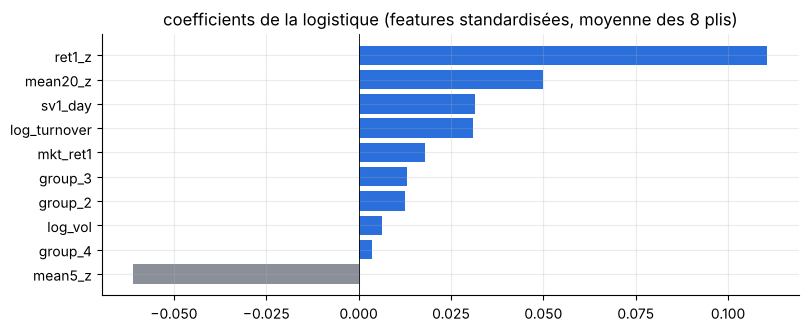

In [7]:
coefs = []
for tr, va in masks:
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(F.loc[tr, COLS], up[tr])
    coefs.append(model[-1].coef_[0])
coefs = pd.DataFrame(coefs, columns=COLS)
summary = pd.DataFrame({'moyenne': coefs.mean(), 'min': coefs.min(), 'max': coefs.max()}).sort_values('moyenne')
print(summary.round(3))

plt.barh(summary.index, summary.moyenne, color=[BLUE if v > 0 else GREY for v in summary.moyenne])
plt.axvline(0, color='k', lw=.6)
plt.title('coefficients de la logistique (features standardisées, moyenne des 8 plis)')
plt.show()

Lecture :
- `ret1_z` domine largement : c'est l'effet « hier » de l'EDA.
- `mean5_z` est négatif alors que `ret1_z` est positif. À rendement d'hier égal, une allocation qui a beaucoup monté
  sur les jours 2 à 5 a tendance à reculer. On retrouve les corrélations négatives des lags 2 à 4 vues en EDA :
  continuation à 1 jour, léger retour en arrière au-delà.
- `mean20_z` est positif : sur un mois, une tendance haussière a tendance à continuer (momentum lent).
- `sv1_day` et `log_turnover` sont positifs.
- `log_vol` et les groupes pèsent peu.

Les huit premiers coefficients gardent le même signe sur les 8 plis (colonnes min et max), seuls les groupes 3 et 4
changent de signe. Le modèle apprend donc des relations stables, pas du bruit d'un pli à l'autre.

## 5. Où le modèle a-t-il raison ?

Une accuracy moyenne de 51,7 % peut cacher des situations très différentes. On classe les prédictions de validation
(dates récentes) par niveau de confiance, c'est-à-dire l'écart de la probabilité à 0,5, et on mesure l'accuracy par décile.

{0: 0.4928, 1: 0.5079, 2: 0.5064, 3: 0.5081, 4: 0.51, 5: 0.5174, 6: 0.523, 7: 0.5237, 8: 0.5323, 9: 0.5558}


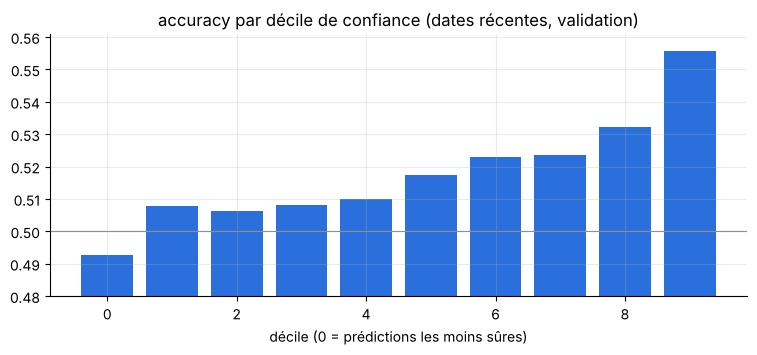

In [8]:
conf, hit = [], []
for tr, va in masks:
    p = logit_fit_predict(COLS)(tr, va)
    r = is_recent[va]
    conf.append(np.abs(p[r]))
    hit.append(((p > 0) == up[va])[r])
conf, hit = np.concatenate(conf), np.concatenate(hit)
by_decile = pd.Series(hit).groupby(pd.qcut(conf, 10, labels=False)).mean()
print(by_decile.round(4).to_dict())

plt.bar(by_decile.index, by_decile.values, color=BLUE)
plt.axhline(.5, color=GREY, lw=.8)
plt.ylim(.48, max(.56, by_decile.max() + .005))
plt.title('accuracy par décile de confiance (dates récentes, validation)')
plt.xlabel('décile (0 = prédictions les moins sûres)')
plt.show()

L'accuracy monte de façon presque régulière avec la confiance : 49,3 % sur le décile le moins sûr, 55,6 % sur le plus sûr.
La moyenne de 51,7 % mélange donc des prédictions utiles et beaucoup de quasi pile-ou-face. Le modèle sait
reconnaître les situations où il a raison. L'enjeu de l'étape d est d'élargir cette zone de confiance.

## Bilan

| | dates récentes | toutes les dates |
|---|---|---|
| règle naïve | 51,57 % | 51,99 % |
| benchmark LightGBM (52 features) | 51,84 % | 52,17 % |
| baseline logistique (10 features) | 51,73 % | 52,19 % |

- La baseline et le benchmark sont au même niveau : la différence (-0,10 point) est très inférieure à son erreur-type (0,24).
  Un modèle linéaire à 10 features lisibles fait aussi bien qu'un LightGBM à 52 features.
- Contre la règle naïve, la baseline gagne 0,17 point, sans passer la règle des deux erreurs-types (t = 0,8).
  Le benchmark, lui, la passe (t = 2,9) : ses gains sont plus réguliers d'un pli à l'autre.
- Presque tout le signal vient de `ret1_z`. Les autres features apportent de petites corrections cohérentes avec l'EDA.

**Référence retenue pour l'étape d : la baseline logistique** (`logit_baseline` dans le journal). À score égal, elle est
plus simple, plus rapide et explicable feature par feature, ce qui compte en entretien. Chaque idée de l'étape d devra la battre
sur les mêmes plis avec la règle des deux erreurs-types.

In [9]:
utils.load_journal()[['modele', 'recent_moy', 'toutes_moy', 'note']].round(4)

,modele,recent_moy,toutes_moy,note
0,naive_ret1,0.5157,0.5199,signe du rendement de la veille
1,benchmark_lgbm,0.5184,0.5217,"notebook officiel QRT, 52 features"
2,logit_baseline,0.5173,0.5219,10 features utils.baseline_features
